# DQN on LunarLander-v3

A DQN agent learns to land the lunar module. The notebook reads top to bottom and must run with *Restart & Run All*.

1. Setup and configuration
2. Environment
3. Random baseline
4. DQN components (replay buffer, network, epsilon, agent)
5. Training
6. Results
7. Experiments
8. Conclusion

## 1. Setup

In [13]:
import os
import random
from collections import Counter

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RETRAIN = True
MODEL_PATH = "dqn_lunarlander.pt"
REWARDS_PATH = "dqn_lunarlander_rewards.npy"

### Configuration

All hyperparameters live in a single dictionary, so an experiment can run with a different configuration without touching the rest of the code.

These values form the **reference configuration**. They are provisional: they will be justified (or changed) by the experiments in section 7.

How they are chosen:
- change **one** parameter at a time, the rest stays at the reference value,
- same training budget and same seeds for every trial,
- same measures: mean score over 100 episodes without exploration, and number of episodes needed to reach a moving average of at least 200.

In [14]:
CONFIG = {
    "gamma": 0.99,
    "learning_rate": 1e-3,
    "batch_size": 64,
    "buffer_capacity": 100_000,
    "eps_start": 1.0,
    "eps_end": 0.01,
    "eps_decay": 0.995,
    "target_update_every": 1000,
    "hidden_size": 128,
    "n_episodes": 600,
}

## 2. Environment

In [15]:
env = gym.make("LunarLander-v3")
env.action_space.seed(SEED)
state, info = env.reset(seed=SEED)
state_dim = env.observation_space.shape[0]
n_actions = env.action_space.n

print("State dimension:", state_dim)
print("Number of actions:", n_actions)

State dimension: 8
Number of actions: 4


## 3. Random baseline

### Random agent

To know whether an agent learns, we need a point of comparison. The random agent picks one of the 4 actions at random at every step, without looking at the state: this is the score to beat.

Agents are classes that define a `run(*, state)` method: `agent.run(state=state)` returns an action. `run_episode` only knows this interface, so the same function plays the random agent and, later, the DQN agent without exploration.

`RandomAgent` still receives `state`, to respect this interface. It uses `random.randrange`, whose generator is seeded, so the baseline is reproducible.

In [16]:
class RandomAgent:
    def __init__(self, *, n_actions):
        self.n_actions = n_actions

    def run(self, *, state):
        return random.randrange(self.n_actions)


random_agent = RandomAgent(n_actions=n_actions)
print("Random action:", random_agent.run(state=state))

Random action: 0


### Playing an episode

`run_episode(env=env, agent=agent)` plays a full episode: `reset`, then `step` in a loop until the end. It returns the total reward, the number of steps and the reason the episode ended.

`agent` is any object with a `run(state=...)` method that returns an action: `RandomAgent` here, and later `DQNAgent` played without exploration. The same function therefore serves every agent.

The loop stops when `terminated` or `truncated` is true, but the two stay separate variables because they do not mean the same thing:
- `terminated`: the episode is really over. Three possible causes: `crash` (the lander body touches the ground), `out_of_viewport` (`abs(x) >= 1`), or `at_rest` (the lander is down and no longer moves).
- `truncated`: the episode was cut at the maximum number of steps, the lander could have kept going.

The crash is tested first: a crash that throws the lander off screen counts as a crash.

`evaluate`, defined right after, replays an agent over several episodes and summarizes its scores. It is first used on the random agent.

In [17]:
def run_episode(*, env, agent, seed=None):
    state, _ = env.reset(seed=seed)
    total_reward = 0.0
    steps = 0

    while True:
        action = agent.run(state=state)
        next_state, reward, terminated, truncated, _ = env.step(action)

        total_reward += reward
        steps += 1

        if terminated or truncated:
            if terminated:
                if env.unwrapped.game_over:
                    reason = "crash"
                elif abs(next_state[0]) >= 1.0:
                    reason = "out_of_viewport"
                else:
                    reason = "at_rest"
            else:
                reason = "truncated"
            return total_reward, steps, reason

        state = next_state

### Evaluating an agent

`evaluate(env=env, agent=agent, n_episodes=N, name=...)` plays `N` episodes with `run_episode`, prints the mean score, the standard deviation, the mean number of steps, the breakdown of end reasons and the number of episodes above the threshold of 200 (`SOLVED`), then returns the list of rewards. The same function evaluates the random baseline and the DQN agent, with exactly the same measures.

In [18]:
N_EVAL = 100
SOLVED = 200


def evaluate(*, env, agent, n_episodes, name="", verbose=True):
    rewards, steps_list, reasons = [], [], []
    for _ in range(n_episodes):
        total_reward, steps, reason = run_episode(env=env, agent=agent)
        rewards.append(total_reward)
        steps_list.append(steps)
        reasons.append(reason)

    if verbose:
        print(f"{name} over {n_episodes} episodes")
        print(f"Mean reward: {np.mean(rewards):.1f}")
        print(f"Std reward:  {np.std(rewards):.1f}")
        print(f"Mean steps:  {np.mean(steps_list):.1f}")
        print("End reasons:", dict(Counter(reasons)))
        print(f"Episodes with reward >= {SOLVED}: {sum(r >= SOLVED for r in rewards)}/{n_episodes}")
    return rewards

Random agent over 100 episodes
Mean reward: -173.4
Std reward:  110.0
Mean steps:  88.2
End reasons: {'crash': 93, 'out_of_viewport': 7}
Episodes with reward >= 200: 0/100


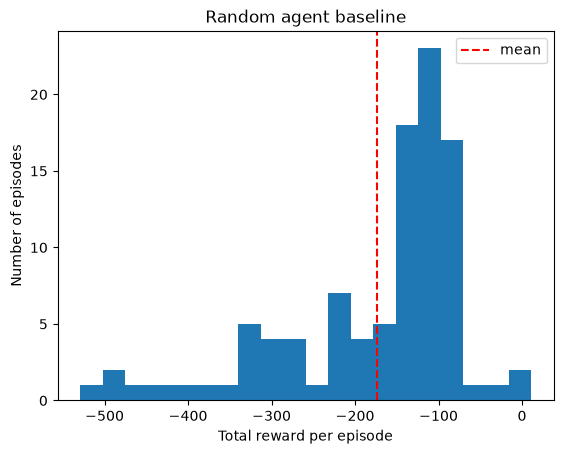

In [19]:
baseline_rewards = evaluate(env=env, agent=random_agent, n_episodes=N_EVAL, name="Random agent")

plt.hist(baseline_rewards, bins=20)
plt.axvline(np.mean(baseline_rewards), color="red", linestyle="--", label="mean")
plt.xlabel("Total reward per episode")
plt.ylabel("Number of episodes")
plt.title("Random agent baseline")
plt.legend()
plt.show()

#### Analysis: random baseline

- **Mean reward: -173.4** (std 110), and **0 episode out of 100** reaches the 200 threshold. This is the score to beat.
- Episodes are **short** (88 steps on average): the random agent does not hover, it falls and hits the ground. The end reasons confirm it: 93 `crash` and 7 `out_of_viewport`, none `at_rest` and none `truncated`.
- The histogram is therefore concentrated on negative values, with a tail towards very bad scores. Nothing comes close to a successful landing.
- Consequence for the rest of the notebook: any agent that lands even a few times will stand out clearly from this distribution.

## 4. DQN components

### Replay buffer

Consecutive steps of an episode look very much alike, so learning in order is unstable. The buffer keeps the latest experiences `(state, action, reward, next_state, done)` up to a fixed capacity (the oldest ones are replaced), and `sample` draws a random batch from it as 5 tensors.

We will store `done = terminated` only: a `truncated` episode is not really over, so its future must still be taken into account in the target.

In [20]:
class ReplayBuffer:
    def __init__(self, *, capacity):
        self.capacity = capacity
        self.buffer = []    

    def __len__(self):
        return len(self.buffer)
    
    def push(self, *, state, action, reward, next_state, done):
        if len(self.buffer) >= self.capacity:
            self.buffer.pop(0)
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, *, batch_size):
        if batch_size > len(self.buffer):
            raise ValueError("Batch size exceeds buffer size.")
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = [], [], [], [], []
        for exp in batch:
            states.append(exp[0])
            actions.append(exp[1])
            rewards.append(exp[2])
            next_states.append(exp[3])
            dones.append(exp[4])

        states = torch.tensor(np.array(states), dtype=torch.float32)
        actions = torch.tensor(actions, dtype=torch.long)
        rewards = torch.tensor(rewards, dtype=torch.float32)
        next_states = torch.tensor(np.array(next_states), dtype=torch.float32)
        dones = torch.tensor(dones, dtype=torch.float32)
        return states, actions, rewards, next_states, dones

### Q-network (neural network)

The network takes the lander state (8 numbers) and returns one Q-value per action (4 numbers). The agent will play the action with the highest Q-value.

```
state (8)  ->  Linear(8, 128)  ->  ReLU  ->  Linear(128, 128)  ->  ReLU  ->  Linear(128, 4)  ->  Q-values (4)
```

- **`Linear`** mixes the input numbers with adjustable weights. These weights are what training adjusts.
- **`ReLU`** sets negative values to 0. Without it, chaining several `Linear` layers would be equivalent to a single `Linear`: the network could only learn very simple relations.
- No `ReLU` at the output: a Q-value can be negative, and we want to read it as is.
- The input size (`state_dim`) and output size (`n_actions`) are read from the environment. The size of the hidden layers (128) is a hyperparameter.

#### Why a class with `forward`, and why we write `network(x)`

`QNetwork` inherits from `nn.Module`, the base class of PyTorch networks.

- In `__init__`, we **build** the layers, once. Their weights live in the object and are modified by training.
- In `forward`, we describe **the computation**: in which order `x` goes through the layers.
- We do not call `network.forward(x)` but `network(x)`. In Python, an object whose class defines `__call__` can be called like a function. `nn.Module` defines this method, and it calls our `forward` while adding some internal PyTorch operations around it (hooks, tracking of computations).

```
network(x)  ->  nn.Module.__call__  ->  QNetwork.forward(x)  ->  self.network(x)  ->  Q-values
```

If we forget to define `forward`, `network(x)` raises a `NotImplementedError`.

Expected shapes: a single state `(8,)` gives `(4,)`, a batch of 32 states `(32, 8)` gives `(32, 4)`. The batch is used for learning, which processes several experiences at once.

In [21]:
from torch import nn


class QNetwork(nn.Module):
    def __init__(self, *, state_dim, n_actions, hidden):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions)
        )
    
    def forward(self, x):
        return self.network(x)
    
network = QNetwork(state_dim=state_dim, n_actions=n_actions, hidden=CONFIG["hidden_size"])
print(network(torch.zeros((1, state_dim))))

tensor([[ 0.0489, -0.0024,  0.0125,  0.1445]], grad_fn=<AddmmBackward0>)


### Epsilon decay

With probability epsilon, the agent plays a random action (exploration). Otherwise it plays the action with the highest Q-value (exploitation). Epsilon starts high and decays, and is 0 during evaluation: the agent no longer explores.

`epsilon_at` computes epsilon **once per episode** (`eps_start * eps_decay ** episode`, with a floor at `eps_end`). The choice of the action itself (`choose_action`) is a method of `DQNAgent`, defined further down.

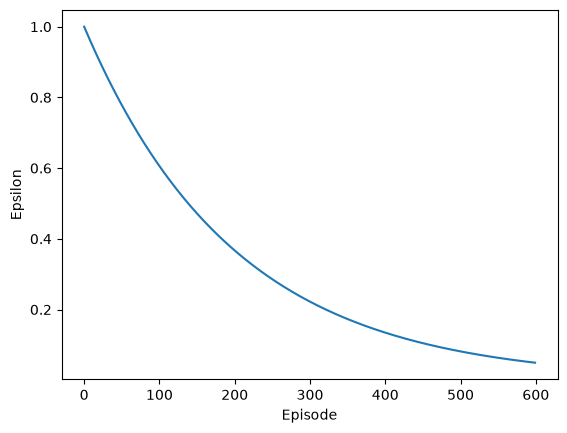

In [22]:

def epsilon_at(*, episode, config):
    eps = config["eps_start"] * config["eps_decay"] ** episode
    return max(config["eps_end"], eps)

epsilons = []
for episode in range(CONFIG["n_episodes"]):
    epsilons.append(epsilon_at(episode=episode, config=CONFIG))

plt.plot(epsilons)
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.show()

#### Analysis: epsilon decay

- The curve is **exponential** (`0.995 ** episode`): it drops fast at the start, then flattens. Epsilon is 0.61 at episode 100, 0.37 at 200, 0.22 at 300, 0.13 at 400, 0.08 at 500 and about 0.05 at the last episode.
- Epsilon only goes below 0.1 around episode 460: **more than three quarters of the training is done with at least 10% random actions**. The agent explores a lot, which is also why the training rewards underestimate its real level.
- The floor `eps_end = 0.01` is **never reached** within 600 episodes (it would need about 920). The agent still plays about 5% random actions at the end of training, hence the experiment of section 7 with a faster decay.

### The DQN agent

`DQNAgent` groups what belongs to a single agent: the network, the target network, the optimizer and the replay buffer. Creating a new agent with a different `config` rebuilds everything cleanly, which will be useful for the experiments in section 7.

| Method | Role |
|---|---|
| `choose_action(state, epsilon)` | epsilon-greedy action |
| `run(state)` | greedy action (epsilon = 0), used by `run_episode` |
| `remember(...)` | stores an experience in the buffer (`done = terminated` only) |
| `learn()` | one learning step on a randomly drawn batch, returns the loss (or `None` if the buffer is too small) |
| `update_target()` | copies `network` into `target_network` |
| `train(env)` | training loop, returns the rewards per episode and the losses |
| `save(path)` / `load(path)` | saves and loads the weights of `network` |

In `learn`, the Bellman target is `reward + gamma * max Q_target(next_state) * (1 - done)`. It is computed under `no_grad`: it is a constant, only `network` is trained. The `target_network` is only copied every `target_update_every` steps, so that the target does not move at every update.

The step counter in `train` is global (it does not restart from 0 at each episode), because the target network copy is counted in total steps.

In [23]:
class DQNAgent:
    def __init__(self, *, state_dim, n_actions, config):
        self.n_actions = n_actions
        self.config = config
        self.network = QNetwork(state_dim=state_dim, n_actions=n_actions, hidden=config["hidden_size"])
        self.target_network = QNetwork(state_dim=state_dim, n_actions=n_actions, hidden=config["hidden_size"])
        self.update_target()
        self.optimizer = torch.optim.Adam(self.network.parameters(), lr=config["learning_rate"])
        self.buffer = ReplayBuffer(capacity=config["buffer_capacity"])

    def run(self, *, state):
        return self.choose_action(state=state, epsilon=0.0)

    def choose_action(self, *, state, epsilon):
        if random.random() < epsilon:
            return random.randrange(self.n_actions)
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            q_values = self.network(state_tensor)
        return torch.argmax(q_values).item()

    def remember(self, *, state, action, reward, next_state, done):
        self.buffer.push(state=state, action=action, reward=reward, next_state=next_state, done=done)

    def learn(self):
        if len(self.buffer) < self.config["batch_size"]:
            return None

        # 1. A batch of past experiences, drawn at random
        states, actions, rewards, next_states, dones = self.buffer.sample(batch_size=self.config["batch_size"])

        # 2. Prediction: what the network believes, for the action actually played
        q_values = self.network(states)
        predicted = []
        for i in range(len(actions)):
            predicted.append(q_values[i, actions[i]])
        predicted = torch.stack(predicted)

        # 3. Bellman target: reward received + estimated value of the future
        #    no_grad: the target is a constant, we do not train the target_network
        with torch.no_grad():
            next_q_values = self.target_network(next_states)
            best_next = next_q_values.max(dim=1).values
            targets = rewards + self.config["gamma"] * best_next * (1 - dones)

        # 4. Gap between prediction and target
        loss = ((predicted - targets) ** 2).mean()

        # 5. Update the weights of network only
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.item()

    def update_target(self):
        self.target_network.load_state_dict(self.network.state_dict())

    def train(self, *, env, verbose=True):
        episode_rewards = []
        losses = []
        total_steps = 0

        for episode in range(self.config["n_episodes"]):
            state, _ = env.reset()
            epsilon = epsilon_at(episode=episode, config=self.config)
            episode_reward = 0

            while True:
                action = self.choose_action(state=state, epsilon=epsilon)
                next_state, reward, terminated, truncated, _ = env.step(action)

                self.remember(state=state, action=action, reward=reward, next_state=next_state, done=terminated)

                loss = self.learn()
                if loss is not None:
                    losses.append(loss)

                total_steps += 1
                if total_steps > self.config["target_update_every"]:
                    self.update_target()        
                    total_steps = 0

                episode_reward += reward
                if terminated or truncated:
                    break
                state = next_state

            episode_rewards.append(episode_reward)
            if verbose:
                print(f"Episode {episode + 1}/{self.config['n_episodes']}, Reward: {episode_reward:.2f}, Epsilon: {epsilon:.3f}")

        return episode_rewards, losses

    def save(self, *, path):
        torch.save(self.network.state_dict(), path)

    def load(self, *, path):
        self.network.load_state_dict(torch.load(path))
        self.update_target()

## 5. Training

We create the agent from `CONFIG`. Then, depending on the `RETRAIN` flag at the top of the notebook, the next cell either trains it and saves it, or loads the model already saved.

- `RETRAIN = False` (default): if `MODEL_PATH` exists, its weights are loaded and nothing is trained, so *Run All* is fast. If the file does not exist, the agent is trained anyway.
- `RETRAIN = True`: the agent is trained again and the saved model is overwritten.
- `agent.train(env=env)` plays `n_episodes` episodes with exploration (decaying epsilon) and learns at every step. It prints one line per episode and returns the rewards per episode (used in section 6) and the losses (not plotted, but available in case of divergence).
- `agent.save(path=...)` writes the network weights to a file, and the training rewards are saved next to it (`REWARDS_PATH`) so the learning curve of section 6 can still be drawn after a load. `agent.load(path=...)` reloads the weights. The losses are not saved: after a load, `losses` is `None`.

In [24]:
agent = DQNAgent(state_dim=state_dim, n_actions=n_actions, config=CONFIG)

if RETRAIN or not os.path.exists(MODEL_PATH):
    episode_rewards, losses = agent.train(env=env)
    agent.save(path=MODEL_PATH)
    np.save(REWARDS_PATH, episode_rewards)
else:
    agent.load(path=MODEL_PATH)
    losses = None
    episode_rewards = np.load(REWARDS_PATH) if os.path.exists(REWARDS_PATH) else None
    print(f"Model loaded from {MODEL_PATH}, no training (set RETRAIN = True to train again).")

Episode 1/600, Reward: -364.15, Epsilon: 1.000
Episode 2/600, Reward: -71.78, Epsilon: 0.995
Episode 3/600, Reward: -158.32, Epsilon: 0.990
Episode 4/600, Reward: -114.57, Epsilon: 0.985
Episode 5/600, Reward: -407.12, Epsilon: 0.980
Episode 6/600, Reward: -95.95, Epsilon: 0.975
Episode 7/600, Reward: 44.81, Epsilon: 0.970
Episode 8/600, Reward: -189.61, Epsilon: 0.966
Episode 9/600, Reward: -130.17, Epsilon: 0.961
Episode 10/600, Reward: -108.58, Epsilon: 0.956
Episode 11/600, Reward: -79.02, Epsilon: 0.951
Episode 12/600, Reward: -123.71, Epsilon: 0.946
Episode 13/600, Reward: -118.52, Epsilon: 0.942
Episode 14/600, Reward: -191.09, Epsilon: 0.937
Episode 15/600, Reward: -77.08, Epsilon: 0.932
Episode 16/600, Reward: -95.62, Epsilon: 0.928
Episode 17/600, Reward: -114.94, Epsilon: 0.923
Episode 18/600, Reward: -129.21, Epsilon: 0.918
Episode 19/600, Reward: -163.07, Epsilon: 0.914
Episode 20/600, Reward: -283.42, Epsilon: 0.909
Episode 21/600, Reward: -217.71, Epsilon: 0.905
Episode 

## 6. Results

Two different measures, not to be confused:
- the **training rewards** (learning curve) are obtained with exploration: they are noisy and underestimate the real level of the agent,
- the **evaluation** replays the agent without exploration (`agent.run`, so epsilon = 0): this is the real score, comparable to the random baseline.

### Learning curve

We plot the reward of each episode and its moving average over 100 episodes. The threshold of 200 is the one from which LunarLander is considered solved.

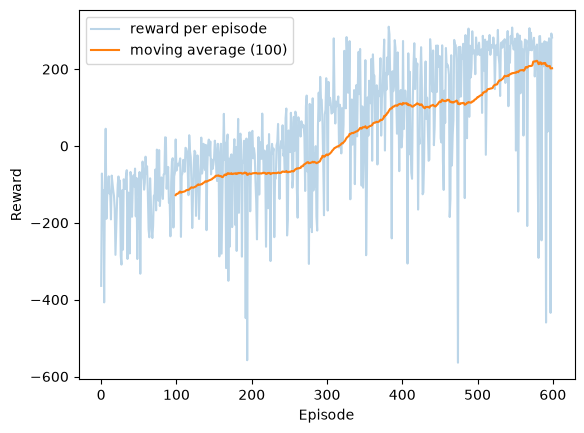

In [25]:
WINDOW = 100

if episode_rewards is None:
    print("No learning curve: the model was loaded and no saved training rewards were found.")
else:
    moving_avg = np.convolve(episode_rewards, np.ones(WINDOW) / WINDOW, mode="valid")

    plt.plot(episode_rewards, alpha=0.3, label="reward per episode")
    plt.plot(np.arange(WINDOW - 1, len(episode_rewards)), moving_avg, label=f"moving average ({WINDOW})")
    plt.xlabel("Episode")
    plt.ylabel("Reward")
    plt.legend()
    plt.show()

### Evaluation without exploration

100 episodes with `agent.run`, same measures as for the random baseline of section 3.

In [26]:
eval_rewards = evaluate(env=env, agent=agent, n_episodes=N_EVAL, name="DQN agent")

DQN agent over 100 episodes
Mean reward: 214.3
Std reward:  69.3
Mean steps:  426.7
End reasons: {'at_rest': 90, 'crash': 4, 'truncated': 6}
Episodes with reward >= 200: 77/100


### Comparison with the baseline

Histogram of the scores of the DQN agent and of the random agent, with their means.

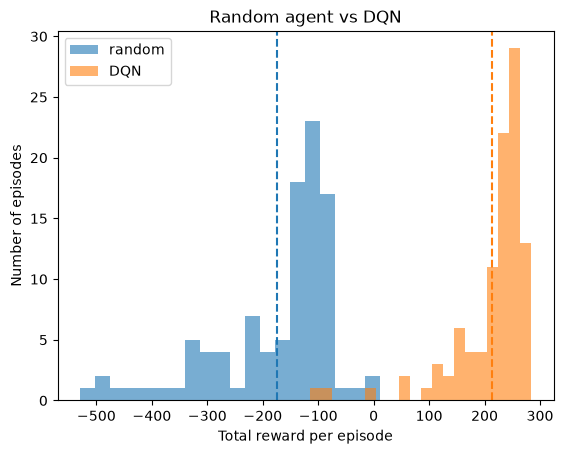

In [27]:
plt.hist(baseline_rewards, bins=20, alpha=0.6, label="random")
plt.hist(eval_rewards, bins=20, alpha=0.6, label="DQN")
plt.axvline(np.mean(baseline_rewards), color="C0", linestyle="--")
plt.axvline(np.mean(eval_rewards), color="C1", linestyle="--")
plt.xlabel("Total reward per episode")
plt.ylabel("Number of episodes")
plt.title("Random agent vs DQN")
plt.legend()
plt.show()

### Visualization

To watch the agent play, we create a **second environment** with `render_mode="human"` (pygame window). The training environment stays without rendering, which keeps it fast. The agent plays without exploration (`agent.run`) through `run_episode`, as for the evaluation.

To replay a saved model without training again: create a `DQNAgent`, then `agent.load(path="dqn_lunarlander.pt")`.

In [ ]:
# N_WATCH = 10

# watch_env = gym.make("LunarLander-v3", render_mode="human")
# for _ in range(N_WATCH):
#     total_reward, steps, reason = run_episode(env=watch_env, agent=agent)
#     print(f"reward = {total_reward:.1f}, steps = {steps}, end = {reason}")
# watch_env.close()

reward = 249.1, steps = 326, end = at_rest
reward = 256.2, steps = 314, end = at_rest
reward = 256.3, steps = 269, end = at_rest
reward = 250.6, steps = 226, end = at_rest
reward = 122.8, steps = 1000, end = truncated
reward = 259.1, steps = 334, end = at_rest
reward = 241.0, steps = 193, end = at_rest
reward = 269.4, steps = 326, end = at_rest
reward = 242.3, steps = 338, end = at_rest
reward = 217.2, steps = 445, end = at_rest


## 7. Experiments

We try to improve the reference configuration. Rules, so that the trials are comparable:
- change **one** parameter at a time, the rest stays at the `CONFIG` value,
- same training budget (`n_episodes`) and same seed for every trial,
- the reference configuration is **replayed** with this same seed in each experiment, to compare trials obtained under the same conditions,
- two measures: the mean score over 100 episodes without exploration (the final level) and the episode at which the moving average reaches 200 (the learning speed).

To keep the notebook readable, the machinery is written once in the next cell. Each experiment then boils down to a small dictionary `{name: modified parameters}` and two calls.

Each trial redoes a full training run: allow several minutes per configuration. A single seed per trial remains fragile in DQN, a small gap may be only noise.

In [29]:
import time


def moving_average(values, *, window):
    return np.convolve(values, np.ones(window) / window, mode="valid")


def run_experiment(*, config, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    exp_env = gym.make("LunarLander-v3")
    exp_env.reset(seed=seed)
    exp_env.action_space.seed(seed)

    exp_agent = DQNAgent(state_dim=state_dim, n_actions=n_actions, config=config)
    train_rewards, _ = exp_agent.train(env=exp_env, verbose=False)
    eval_rewards = evaluate(env=exp_env, agent=exp_agent, n_episodes=N_EVAL, verbose=False)
    exp_env.close()

    avg = moving_average(train_rewards, window=WINDOW)
    reached = np.flatnonzero(avg >= SOLVED)
    return {
        "moving_avg": avg,
        "eval_mean": np.mean(eval_rewards),
        "eval_std": np.std(eval_rewards),
        "solved_at": reached[0] + WINDOW if len(reached) > 0 else None,
    }


def run_experiments(*, experiments, seed):
    results = {}
    for name, changes in experiments.items():
        start = time.time()
        results[name] = run_experiment(config={**CONFIG, **changes}, seed=seed)
        print(f"{name}: done in {time.time() - start:.0f}s")
    return results


def show_results(*, results):
    print(f"{'config':<28}{'eval mean':>10}{'eval std':>10}{'solved at':>11}")
    for name, r in results.items():
        solved_at = r["solved_at"] if r["solved_at"] is not None else "never"
        print(f"{name:<28}{r['eval_mean']:>10.1f}{r['eval_std']:>10.1f}{solved_at:>11}")

    for name, r in results.items():
        plt.plot(np.arange(WINDOW - 1, WINDOW - 1 + len(r["moving_avg"])), r["moving_avg"], label=name)
    plt.axhline(SOLVED, color="red", linestyle="--")
    plt.xlabel("Episode")
    plt.ylabel(f"Reward (moving average {WINDOW})")
    plt.legend()
    plt.show()

### Experiment 1: epsilon decay speed (`eps_decay`)

With `eps_decay = 0.995`, epsilon is still 0.05 at episode 600: the agent plays 5% random actions until the end, and the moving average only passes 200 very close to the end (episode 564). A faster decay leaves more episodes to exploitation. We test 0.99 and 0.98 (epsilon drops below 0.05 around episode 300 and 150).

In [30]:
experiments_eps_decay = {
    "eps_decay=0.995 (ref)": {},
    "eps_decay=0.99": {"eps_decay": 0.99},
    "eps_decay=0.98": {"eps_decay": 0.98},
}

results_eps_decay = run_experiments(experiments=experiments_eps_decay, seed=SEED)
show_results(results=results_eps_decay)

eps_decay=0.995 (ref): done in 1355s


KeyboardInterrupt: 

#### Analysis: experiment 1 (`eps_decay`)

| config | eval mean | eval std | solved at |
|---|---|---|---|
| 0.995 (ref) | 214.0 | 68.4 | never |
| 0.99 | 114.7 | 133.0 | 419 |
| 0.98 | 186.8 | 107.5 | 481 |

**What the learning curves show**
- A faster decay **speeds up learning**: with 0.99 the moving average crosses 200 around episode 420 and stays between about 210 and 230. With 0.98 it crosses 200 at episode 481. The reference (0.995) only reaches about 155 at episode 600, so it never crosses the threshold in this run.
- The speed is not monotonic: 0.98 is slower than 0.99. Decaying too fast means less exploration, and the agent stagnates (the 0.98 curve even drops back to about 0 around episodes 300 to 320 before recovering).
- All curves start from the same place (about -115), so the gap comes from the exploration schedule and not from the starting point.

**What the evaluation shows (and contradicts)**
- The ranking by final score is **the opposite** of the ranking by learning speed: the reference has the best evaluation (214.0, the only mean above 200) while 0.99, the fastest learner, has the worst (114.7) and a very large std (133).
- Both measures are not the same thing: the curve is a moving average of the 100 last training episodes (with exploration, weights that kept changing), whereas the evaluation tests only the **final weights**, once. A DQN policy can degrade in the last episodes, and with a std of 133 a mean over 100 episodes is itself uncertain.

**Conclusion and limits**
- Nothing here allows to say that 0.995 is better: it is the best on one measure and the worst on the other, with **one seed per configuration**. The differences between 214 and 187 are within the std of the evaluations.
- To conclude, the experiment should be repeated with several seeds (for example 3 to 5) and report the mean and the spread, and/or keep the best weights seen during training instead of the last ones.

### Experiment 2: learning rate (`learning_rate`)

Experiment 1 showed an unstable final policy (evaluation std up to 133). The learning rate sets the size of each weight update: with `learning_rate = 1e-3`, a single noisy batch can degrade a policy that was good. A smaller value should give more stable final weights, at the price of slower learning. We test 5e-4 and 1e-4.

In [ ]:
experiments_lr = {
    "learning_rate=1e-3 (ref)": {},
    "learning_rate=5e-4": {"learning_rate": 5e-4},
    "learning_rate=1e-4": {"learning_rate": 1e-4},
}

results_lr = run_experiments(experiments=experiments_lr, seed=SEED)
show_results(results=results_lr)